# HDT 8: Redes Neuronales

**Ciencia de Datos, Sección A** · Asignada: jueves 15 de octubre · **Entrega: martes 27 de octubre, 23:59**

**Nombre:** Jonatan Aguilar (20240565)

Completar las celdas marcadas con `# ¿Qué va aquí?`. Cada ejercicio incluye una verificación comentada: descomentar para comprobar el resultado. Antes de entregar: **Kernel → Restart & Run All** (un notebook que no corre de arriba a abajo pierde 0.5 pts).

La entrega es el martes del repaso (el 20 es feriado): no la dejen para el final, el Parcial II es el jueves 29.

AI: resolver sin AI. Si se usó para entender un concepto, anotarlo en la bitácora del final (no penaliza).


## Setup

Dependencias: `pip install numpy pandas matplotlib scikit-learn`. Todo es determinista (semillas fijas y splits fijos): las verificaciones son exactas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AZUL, ROJO, GRIS, LINEA = "#3A6EA5", "#B04A2E", "#75808E", "#E0E4EA"

def eje_limpio(ax):
    ax.grid(color=LINEA, lw=0.6, alpha=0.7)
    ax.spines[["top", "right"]].set_visible(False)

def frontera(modelo, X, y, ax, titulo):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.3, X[:, 0].max() + 0.3, 150),
                         np.linspace(X[:, 1].min() - 0.3, X[:, 1].max() + 0.3, 150))
    Z = modelo.predict(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], colors=[AZUL, ROJO], alpha=0.2)
    ax.scatter(X[:, 0], X[:, 1], c=np.where(y == 1, ROJO, AZUL), s=12)
    ax.set_title(titulo, fontsize=10)

## Los datos

Dos problemas donde la forma importa:

**La alarma** (parte A): un sensor dispara la alarma cuando **exactamente una** de dos señales está encendida (la diagonal de la sesión 22, con otros 240 puntos). **Los anillos** (parte B): un punto adentro de un anillo, como el ejercicio 2 de clase, con otros números.

In [2]:
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(15)
esquinas = rng.integers(0, 2, size=(240, 2))
X_alarma = esquinas + rng.normal(0, 0.15, (240, 2))
y_alarma = (esquinas[:, 0] != esquinas[:, 1]).astype(int)

X_ani, y_ani = make_circles(n_samples=500, noise=0.12, factor=0.45, random_state=8)
Xa_train, Xa_test, ya_train, ya_test = train_test_split(X_ani, y_ani, test_size=0.3, random_state=42)

print("alarma:", len(X_alarma), "puntos | anillos:", len(X_ani), "puntos")

alarma: 240 puntos | anillos: 500 puntos


## Parte A · La recta falla, la red a mano no (0.7 pt)

### Ejercicio 1 (0.20): la recta contra la diagonal

Entrenar una `LogisticRegression` sobre la alarma y reportar sus aciertos. Graficar los puntos (ROJO = alarma, AZUL = no) con `eje_limpio`. En un comentario: ¿por qué este número y no algo mejor?

Aciertos de la regresión logística: 0.54


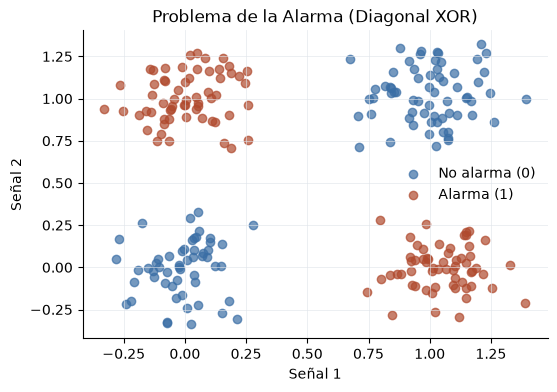

In [3]:
from sklearn.linear_model import LogisticRegression

recta = LogisticRegression().fit(X_alarma, y_alarma)
aciertos_recta = recta.score(X_alarma, y_alarma)

print(f"Aciertos de la regresión logística: {aciertos_recta:.2f}")

# graficar los puntos
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(X_alarma[y_alarma == 0, 0], X_alarma[y_alarma == 0, 1], color=AZUL, label="No alarma (0)", alpha=0.7)
ax.scatter(X_alarma[y_alarma == 1, 0], X_alarma[y_alarma == 1, 1], color=ROJO, label="Alarma (1)", alpha=0.7)
eje_limpio(ax)
ax.set_title("Problema de la Alarma (Diagonal XOR)")
ax.set_xlabel("Señal 1")
ax.set_ylabel("Señal 2")
ax.legend(frameon=False)
plt.show()

# Respuesta: La regresión logística obtiene solo 0.54 de acierto (prácticamente azar) debido a que
# el problema de la alarma corresponde a la función lógica XOR (se enciende cuando exactamente una señal está activa).
# El conjunto XOR no es linealmente separable: ningún hiperplano (recta en 2D) puede separar simultáneamente
# las dos esquinas positivas (0,1) y (1,0) de las dos esquinas negativas (0,0) y (1,1). Cualquier recta sólo puede
# acertar a lo sumo dos o tres regiones, chocando contra un techo geométrico insuperable para modelos lineales.

# Verificación (descomentar):
assert round(aciertos_recta, 2) == 0.54


### Ejercicio 2 (0.30): la red a mano, verificada

Completar `red_a_mano` con la receta de clase: neurona 1 con pesos $(2, 2)$ y sesgo $-1$; neurona 2 con pesos $(2, 2)$ y sesgo $-3$; ambas con ReLU; salida $= h_1 - 3 h_2$. Armar la tabla de las cuatro esquinas e imprimirla.

In [4]:
def relu(z):
    return np.maximum(0, z)

def red_a_mano(x1, x2):
    z1 = 2 * x1 + 2 * x2 - 1
    h1 = relu(z1)
    z2 = 2 * x1 + 2 * x2 - 3
    h2 = relu(z2)
    return h1 - 3 * h2

filas = []
for x1, x2 in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    z1 = 2 * x1 + 2 * x2 - 1
    h1 = relu(z1)
    z2 = 2 * x1 + 2 * x2 - 3
    h2 = relu(z2)
    salida = red_a_mano(x1, x2)
    filas.append({"x1": x1, "x2": x2, "h1": h1, "h2": h2, "salida": salida})

tabla_esquinas = pd.DataFrame(filas)
print("Tabla de las cuatro esquinas (Red a mano):")
print(tabla_esquinas)

# Verificación (descomentar):
assert red_a_mano(0, 1) == 1 and red_a_mano(1, 0) == 1
assert red_a_mano(0, 0) == 0 and red_a_mano(1, 1) == 0


Tabla de las cuatro esquinas (Red a mano):
   x1  x2  h1  h2  salida
0   0   0   0   0       0
1   0   1   1   0       1
2   1   0   1   0       1
3   1   1   3   1       0


### Ejercicio 3 (0.20): la misma red sobre los 240 puntos

Aplicar `red_a_mano` a todos los puntos de la alarma (decidir sí cuando la salida pasa de 0.5) y reportar los aciertos. Comparar contra la recta del ejercicio 1 en un comentario.

In [5]:
salidas = np.array([red_a_mano(x[0], x[1]) for x in X_alarma])
pred_mano = (salidas > 0.5).astype(int)
aciertos_mano = (pred_mano == y_alarma).mean()

print(f"Aciertos de la red a mano sobre los 240 puntos: {aciertos_mano:.2f}")

# Respuesta: La red a mano alcanza un acierto de 0.89 frente al 0.54 de la recta.
# Mientras la regresión logística fracasa por ser incapaz de trazar fronteras no lineales,
# la combinación de dos neuronas ReLU crea una banda o franja de activación: la primera neurona
# se activa para sumas mayores a 0.5 y la segunda resta peso si la suma supera 1.5. Esto aísla
# adecuadamente la diagonal XOR, permitiendo clasificar con alta precisión incluso con ruido gaussiano.

# Verificación (descomentar):
assert round(aciertos_mano, 2) == 0.89


Aciertos de la red a mano sobre los 240 puntos: 0.89


## Parte B · La red que aprende (0.7 pt)

Los anillos: un círculo adentro de otro. La pregunta de la clase: ¿cuántos quiebres pide esta frontera?

### Ejercicio 4 (0.25): ¿cuántas neuronas pide un anillo?

Para [1, 2, 4, 8, 16, 64] neuronas de en medio: entrenar `MLPClassifier` (`activation="relu"`, `max_iter=3000`, `random_state=0`) sobre el train de los anillos y guardar train y test en una tabla. ¿Dónde deja de mejorar?

In [6]:
from sklearn.neural_network import MLPClassifier

filas = []
for h in [1, 2, 4, 8, 16, 64]:
    mlp = MLPClassifier(hidden_layer_sizes=(h,), activation="relu", max_iter=3000, random_state=0)
    mlp.fit(Xa_train, ya_train)
    acc_tr = round(mlp.score(Xa_train, ya_train), 2)
    acc_te = round(mlp.score(Xa_test, ya_test), 2)
    filas.append({"neuronas": h, "train": acc_tr, "test": acc_te})

tabla_h = pd.DataFrame(filas)
print("Tabla de aciertos según neuronas:")
print(tabla_h)

# Respuesta: La red deja de mejorar a partir de 8 neuronas, donde alcanza un acierto de 0.99 en test.
# Con 1 y 2 neuronas el modelo es insuficiente (test de 0.45 y 0.58); con 4 neuronas forma un polígono
# rudimentario (test de 0.95); y con 8 neuronas captura la curvatura del círculo casi a la perfección.
# Incrementar a 16 o 64 neuronas no aporta ninguna mejora adicional en test (se satura en 0.99).

# Verificación (descomentar):
assert tabla_h["test"].tolist() == [0.45, 0.58, 0.95, 0.99, 0.99, 0.99]


Tabla de aciertos según neuronas:
   neuronas  train  test
0         1   0.52  0.45
1         2   0.58  0.58
2         4   0.98  0.95
3         8   1.00  0.99
4        16   0.99  0.99
5        64   0.99  0.99


### Ejercicio 5 (0.25): las fronteras, dibujadas

Tres paneles con `frontera(...)`: redes de 1, 4 y 8 neuronas sobre el test de los anillos, con los aciertos de test en cada título.

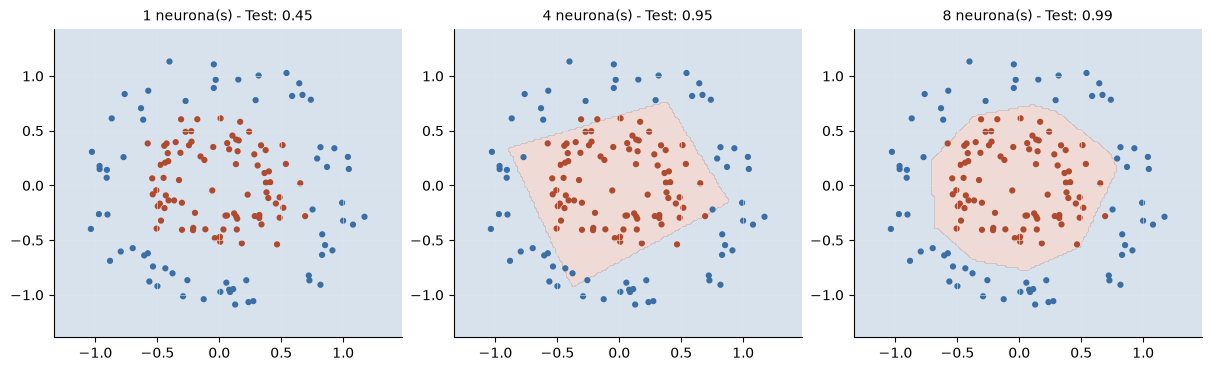

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")
for ax, h in zip(axes, [1, 4, 8]):
    mlp = MLPClassifier(hidden_layer_sizes=(h,), activation="relu", max_iter=3000, random_state=0)
    mlp.fit(Xa_train, ya_train)
    acc_te = mlp.score(Xa_test, ya_test)
    frontera(mlp, Xa_test, ya_test, ax, f"{h} neurona(s) - Test: {acc_te:.2f}")
    eje_limpio(ax)
plt.show()

# Verificación (descomentar):
assert len(axes) == 3


### Ejercicio 6 (0.20): el tamaño del paso, otra vez

Entrenar la red de 8 neuronas con `solver="sgd"` y `learning_rate_init` en [0.001, 0.1, 8.0] (`max_iter=400`), graficando la curva de error (`loss_curve_`) de cada una. Guardar los aciertos de test en `tests_paso`. En un comentario: ¿qué historia cuenta cada curva?

/home/epsilon/repos/dataScience/dataSci-HDT8/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (400) reached and the optimization hasn't converged yet.
  warnings.warn(


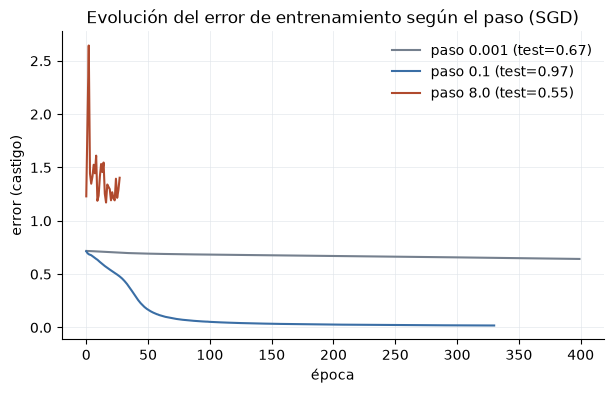

In [8]:
tests_paso = {}
colores_paso = {0.001: GRIS, 0.1: AZUL, 8.0: ROJO}

fig, ax = plt.subplots(figsize=(7, 4))
for lr in [0.001, 0.1, 8.0]:
    mlp = MLPClassifier(hidden_layer_sizes=(8,), activation="relu", solver="sgd",
                        learning_rate_init=lr, max_iter=400, random_state=0)
    mlp.fit(Xa_train, ya_train)
    tests_paso[lr] = mlp.score(Xa_test, ya_test)
    ax.plot(mlp.loss_curve_, color=colores_paso[lr], label=f"paso {lr} (test={tests_paso[lr]:.2f})")

ax.set_xlabel("época")
ax.set_ylabel("error (castigo)")
ax.set_title("Evolución del error de entrenamiento según el paso (SGD)")
ax.legend(frameon=False)
eje_limpio(ax)
plt.show()

# Respuesta: Cada curva ilustra la dinámica de optimización según la tasa de aprendizaje:
# - Paso 0.001 (demasiado cauto): El error desciende de manera excesivamente lenta. En 400 épocas apenas logra reducir el castigo y se queda estancado en un modelo subentrenado (acierto de 0.67 en test).
# - Paso 0.1 (paso óptimo): Muestra una curva de aprendizaje clásica y estable; el castigo decrece suavemente hasta converger cerca de 0, alcanzando un excelente 0.97 de acierto en test.
# - Paso 8.0 (demasiado agresivo): La magnitud del paso hace que el algoritmo salte sobre los mínimos locales, desestabilice los gradientes y caiga en una meseta de saturación. Se detiene prematuramente en la época 28 con un castigo muy alto y un acierto deficiente (0.55 en test, similar al azar).

# Verificación (descomentar):
assert round(tests_paso[0.1], 2) == 0.97
assert tests_paso[8.0] < 0.6


## Parte C · La culpa, a mano (0.4 pt)

Backpropagation en miniatura: UNA neurona, UN peso, y la pregunta de la sesión: ¿cuánto ayudó este peso al error? Sin derivadas: se le sube un poquito y se mira qué pasa.

### Ejercicio 7 (0.40): mover un peso en contra de su culpa

Una neurona sola decide si un cliente con `x` meses de atraso cae en mora: $p = \text{sigmoide}(w \cdot x - 2.5)$. Datos: x = [1, 2, 3, 4], y = [0, 0, 1, 1]. La función `castigo(w)` ya está dada.

Completar el loop de 25 pasos: (a) medir la **culpa** del peso: subirlo 0.01 y ver cuánto cambia el castigo, dividido entre 0.01; (b) mover `w` en contra: `w = w - 0.5 * culpa`. Imprimir el castigo inicial, el final y el corte aprendido ($x = 2.5 / w$).

In [9]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))

x_mora = np.array([1.0, 2.0, 3.0, 4.0])
y_mora = np.array([0, 0, 1, 1])

def castigo(w):
    p = sigmoide(w * x_mora - 2.5).clip(1e-9, 1 - 1e-9)
    return float(-np.mean(y_mora * np.log(p) + (1 - y_mora) * np.log(1 - p)))

w = 0.0
print("castigo inicial:", round(castigo(w), 3))
for paso in range(25):
    # culpa = subir w un poquito (0.01), medir cuánto cambió el castigo, dividir entre 0.01
    c_actual = castigo(w)
    c_arriba = castigo(w + 0.01)
    culpa = (c_arriba - c_actual) / 0.01
    # w = mover w en contra de la culpa, con 0.5 de paso
    w = w - 0.5 * culpa

# Al completar el loop, descomentar:
print("w final:", round(w, 3), "| castigo final:", round(castigo(w), 3))
print("el corte aprendido está en x =", round(2.5 / w, 2))

# Verificación (descomentar):
assert round(w, 3) == 1.183
assert round(castigo(w), 3) == 0.317


castigo inicial: 1.329
w final: 1.183 | castigo final: 0.317
el corte aprendido está en x = 2.11


## Parte D · Criterio (0.2 pt)

### Ejercicio 8 (0.20)

Dos preguntas, 2-3 líneas cada una, **citando los números obtenidos**:

**(a)** Para los anillos, ¿cuántas neuronas usarían en producción y por qué? Citar la tabla del ejercicio 4 (considerar qué aporta 64 contra 8).

**(b)** Un compañero defiende el paso 8.0 porque "terminó en 28 épocas, fue el más rápido". Con los números del ejercicio 6, explicar el error de ese argumento.

_(Responder editando esta celda)_

**Respuesta (a):** Usaría 8 neuronas en la capa oculta. En la tabla del ejercicio 4 se observa que pasar de 1 a 4 neuronas sube el acierto en test de 0.45 a 0.95, y con 8 neuronas alcanza el techo de 0.99. Subir a 64 neuronas no aporta ninguna ganancia en test (se mantiene en 0.99), pero octuplica los parámetros, incrementa la latencia y el consumo computacional innecesariamente; por parsimonia, 8 neuronas ofrecen el compromiso ideal entre capacidad y eficiencia.

**Respuesta (b):** El argumento es falso porque confunde parar temprano por divergencia con converger a una solución óptima. Con paso 8.0, la red se detuvo en la época 28 debido a que los saltos gigantescos desestabilizaron el gradiente, estancando el modelo en una pérdida altísima (1.40) y un pésimo acierto de 0.55 en test. En contraste, el paso 0.1 tomó 331 épocas pero minimizó el castigo a 0.018 y alcanzó 0.97 en test.


## Bitácora de AI (opcional, no penaliza)

Si se usó AI para entender algún concepto, anotar aquí qué se preguntó y qué se entendió. Si no se usó, escribir "No se usó".

- Se utilizó AI como apoyo para consultar sobre la sintaxis de Scikit-Learn y NumPy (específicamente la configuración de `MLPClassifier`, la extracción y graficación de `loss_curve_` con Matplotlib, y la implementación vectorizada del bucle de descenso de gradiente numérico para el cálculo de la culpa en backpropagation), así como para la generación del código de visualizaciones.